[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shahin1717/ai-roadmap/blob/main/math/linear-algebra/singular-value-decomposition/notebook.ipynb)

# Singular Value Decomposition: hands-on

This notebook goes with the [topic README](README.md). You will push a circle through a matrix and watch rotate, stretch, rotate; check $A = U\Sigma V^\top$ and its link to $A^\top A$; compare the full and thin shapes; read the four subspaces, the rank, and the condition number off the SVD; build the pseudoinverse and the minimum-norm solution; check the Eckart-Young result; compress a synthetic image; run PCA through the SVD; factorize a small rating matrix; and count the parameters of a compressed weight matrix and of a LoRA update. All data are synthetic. It uses NumPy, Matplotlib, `scipy.linalg`, and (only for a cross-check) scikit-learn, and runs in a few seconds on a CPU.

Numerical checks hold only up to rounding error, so we compare with `np.allclose`, never with `==`. Signs of singular vectors can differ between programs, because flipping $\mathbf{u}_i$ and $\mathbf{v}_i$ together gives an equally valid SVD.

In [1]:
%matplotlib inline
import numpy as np
import scipy.linalg as sla
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 70
plt.rcParams["axes.titlesize"] = 11
np.set_printoptions(precision=4, suppress=True)

## 1. A matrix maps the circle to an ellipse

Take the matrix $A$ below and apply it to 24 unit vectors around the circle. The image is an ellipse. The SVD finds its axes: the half-axes are $\sigma_1\mathbf{u}_1$ and $\sigma_2\mathbf{u}_2$, and the input directions $\mathbf{v}_1, \mathbf{v}_2$ are the ones that land exactly on them: $A\mathbf{v}_i = \sigma_i\mathbf{u}_i$.

In [2]:
A = np.array([[3.0, 0.0],
              [4.0, 5.0]])
U, s, Vt = np.linalg.svd(A)
V = Vt.T
print("singular values:", s, "  (3 sqrt(5) =", round(3 * np.sqrt(5), 4), ", sqrt(5) =", round(np.sqrt(5), 4), ")")
print("U =\n", U)
print("V =\n", V)
for i in range(2):
    print(f"A v{i+1} = {A @ V[:, i]}    sigma{i+1} u{i+1} = {s[i] * U[:, i]}")

singular values: [6.7082 2.2361]   (3 sqrt(5) = 6.7082 , sqrt(5) = 2.2361 )
U =
 [[-0.3162 -0.9487]
 [-0.9487  0.3162]]
V =
 [[-0.7071 -0.7071]
 [-0.7071  0.7071]]
A v1 = [-2.1213 -6.364 ]    sigma1 u1 = [-2.1213 -6.364 ]
A v2 = [-2.1213  0.7071]    sigma2 u2 = [-2.1213  0.7071]


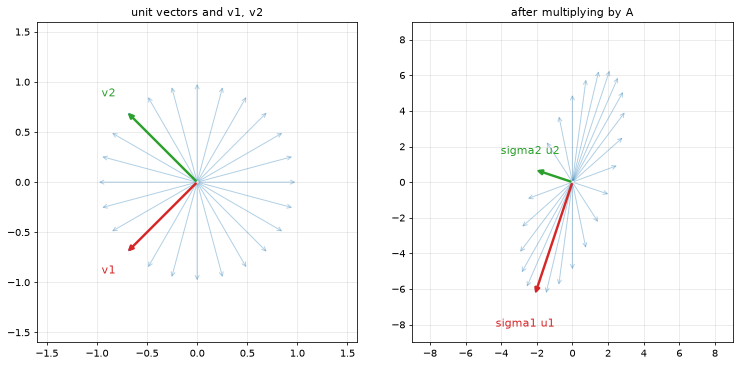

In [3]:
angles = np.linspace(0, 2 * np.pi, 24, endpoint=False)
circle = np.vstack([np.cos(angles), np.sin(angles)])        # 24 unit vectors as columns
image = A @ circle

fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
for ax, pts, title in [(axes[0], circle, "unit vectors and v1, v2"), (axes[1], image, "after multiplying by A")]:
    for k in range(pts.shape[1]):
        ax.annotate("", xy=pts[:, k], xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="C0", alpha=0.35, lw=1))
    ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.set_title(title)
for i, color in enumerate(["C3", "C2"]):
    axes[0].annotate("", xy=V[:, i], xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=color, lw=2.5))
    axes[1].annotate("", xy=s[i] * U[:, i], xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=color, lw=2.5))
for i, color in enumerate(["C3", "C2"]):
    axes[0].text(*(1.25 * V[:, i]), f"v{i+1}", color=color, fontsize=11, ha="center", va="center")
    axes[1].text(*(1.25 * s[i] * U[:, i] + (0.9 if i == 1 else 0.0) * np.array([U[1, i], -U[0, i]])), f"sigma{i+1} u{i+1}", color=color, fontsize=11, ha="center", va="center")
axes[0].set_xlim(-1.6, 1.6); axes[0].set_ylim(-1.6, 1.6)
axes[1].set_xlim(-9, 9); axes[1].set_ylim(-9, 9)
plt.tight_layout()
plt.show()

The red arrow on the left ($\mathbf{v}_1$) is sent to the long red arrow on the right ($\sigma_1\mathbf{u}_1$), and the green arrow to the short green one. Both pairs are perpendicular.

## 2. Rotate, stretch, rotate, step by step

$A = U\Sigma V^\top$ acts on a vector from right to left. We follow a colored circle through the three factors. After $V^\top$ it is still a circle (only turned or flipped). After $\Sigma$ it is an ellipse lined up with the axes. After $U$ it is the ellipse that $A$ really makes. First we check the factorization itself.

In [4]:
Sigma = np.diag(s)
print("U Sigma V^T equals A:", np.allclose(U @ Sigma @ Vt, A))
print("U orthogonal:", np.allclose(U.T @ U, np.eye(2)), "| V orthogonal:", np.allclose(V.T @ V, np.eye(2)))
print("det U =", round(np.linalg.det(U), 4), ", det V^T =", round(np.linalg.det(Vt), 4), "(-1 means a reflection is involved)")
print("sigma1 * sigma2 =", round(s.prod(), 4), "| |det A| =", round(abs(np.linalg.det(A)), 4))

U Sigma V^T equals A: True
U orthogonal: True | V orthogonal: True
det U = -1.0 , det V^T = -1.0 (-1 means a reflection is involved)
sigma1 * sigma2 = 15.0 | |det A| = 15.0


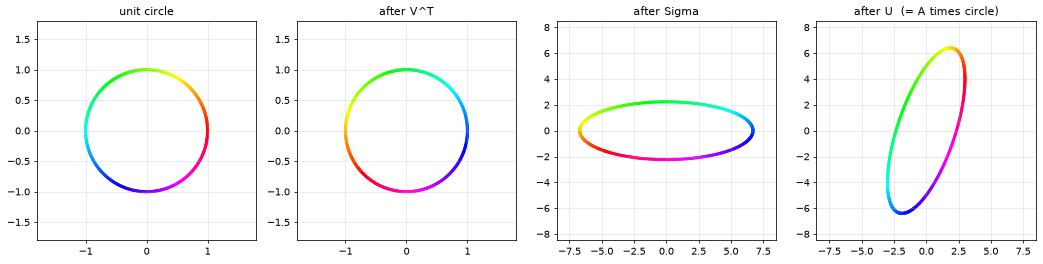

same final shape as A @ ring: True


In [5]:
t = np.linspace(0, 2 * np.pi, 400)
ring = np.vstack([np.cos(t), np.sin(t)])
colors = plt.cm.hsv(t / (2 * np.pi))
stages = [ring, Vt @ ring, Sigma @ Vt @ ring, U @ Sigma @ Vt @ ring]
titles = ["unit circle", "after V^T", "after Sigma", "after U  (= A times circle)"]

fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
for ax, P, title in zip(axes, stages, titles):
    ax.scatter(P[0], P[1], c=colors, s=5)
    lim = 1.8 if abs(P).max() < 1.5 else 8.5
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.set_title(title)
plt.tight_layout()
plt.show()
print("same final shape as A @ ring:", np.allclose(stages[-1], A @ ring))

Follow one color around. Where the order of the colors is reversed between two panels, a reflection happened (here the determinants of $U$ and $V^\top$ are negative, so each flips the picture).

## 3. Full versus thin SVD

For a tall $m \times n$ matrix the full SVD has a square $U$ ($m \times m$) and an $m \times n$ matrix $\Sigma$ with zero rows at the bottom. The thin SVD drops the columns of $U$ that only multiply those zero rows. Both reproduce $A$. NumPy's `full_matrices=False` gives the thin version, and `scipy.linalg.diagsvd` builds the rectangular $\Sigma$.

In [6]:
rng = np.random.default_rng(0)
for shape in [(5, 3), (3, 5), (4, 4)]:
    X = rng.normal(size=shape)
    Uf, sf, Vtf = np.linalg.svd(X)
    Ut, st, Vtt = np.linalg.svd(X, full_matrices=False)
    Sig_full = sla.diagsvd(sf, *shape)
    print(f"A is {shape}:  full U {Uf.shape}, Sigma {Sig_full.shape}, Vt {Vtf.shape}   |   thin U {Ut.shape}, Sigma ({len(st)}, {len(st)}), Vt {Vtt.shape}")
    print("   both rebuild A:", np.allclose(Uf @ Sig_full @ Vtf, X), np.allclose(Ut @ np.diag(st) @ Vtt, X))

X = rng.normal(size=(5, 3))
print("\nSigma of a 5 x 3 matrix in the full SVD:\n", sla.diagsvd(np.linalg.svd(X, compute_uv=False), 5, 3))

A is (5, 3):  full U (5, 5), Sigma (5, 3), Vt (3, 3)   |   thin U (5, 3), Sigma (3, 3), Vt (3, 3)
   both rebuild A: True True
A is (3, 5):  full U (3, 3), Sigma (3, 5), Vt (5, 5)   |   thin U (3, 3), Sigma (3, 3), Vt (3, 5)
   both rebuild A: True True
A is (4, 4):  full U (4, 4), Sigma (4, 4), Vt (4, 4)   |   thin U (4, 4), Sigma (4, 4), Vt (4, 4)
   both rebuild A: True True

Sigma of a 5 x 3 matrix in the full SVD:
 [[3.4355 0.     0.    ]
 [0.     2.2054 0.    ]
 [0.     0.     0.9008]
 [0.     0.     0.    ]
 [0.     0.     0.    ]]


## 4. Singular values and the eigenvalues of $A^\top A$

Multiplying $A = U\Sigma V^\top$ by its transpose gives $A^\top A = V\Sigma^\top\Sigma V^\top$: the spectral theorem for a symmetric matrix. So the singular values are the square roots of the eigenvalues of $A^\top A$, the columns of $V$ are its eigenvectors, and the columns of $U$ are eigenvectors of $AA^\top$. Eigenvectors are only defined up to sign, so we compare absolute values of dot products.

In [7]:
lam, Vlam = np.linalg.eigh(A.T @ A)                 # ascending order
order = np.argsort(lam)[::-1]
lam, Vlam = lam[order], Vlam[:, order]
print("eigenvalues of A^T A:", lam, "| square roots:", np.sqrt(lam), "| singular values:", s)
print("v_i match eigenvectors of A^T A (up to sign):", [bool(np.isclose(abs(Vlam[:, i] @ V[:, i]), 1)) for i in range(2)])

lam_u, Ulam = np.linalg.eigh(A @ A.T)
order = np.argsort(lam_u)[::-1]
Ulam = Ulam[:, order]
print("u_i match eigenvectors of A A^T (up to sign):", [bool(np.isclose(abs(Ulam[:, i] @ U[:, i]), 1)) for i in range(2)])
w_eig, V_eig = np.linalg.eig(A)
print("\neigenvalues of A itself:", np.sort(w_eig), " (not the singular values)")
print("eigenvectors of A are not perpendicular, dot product =", round(V_eig[:, 0] @ V_eig[:, 1], 4))

S_sym = np.array([[2.0, 0.0], [0.0, -3.0]])
print("\nsymmetric matrix with eigenvalues 2 and -3 has singular values", np.linalg.svd(S_sym, compute_uv=False))

eigenvalues of A^T A: [45.  5.] | square roots: [6.7082 2.2361] | singular values: [6.7082 2.2361]
v_i match eigenvectors of A^T A (up to sign): [True, True]
u_i match eigenvectors of A A^T (up to sign): [True, True]

eigenvalues of A itself: [3. 5.]  (not the singular values)
eigenvectors of A are not perpendicular, dot product = -0.8944

symmetric matrix with eigenvalues 2 and -3 has singular values [3. 2.]


**Why we do not compute the SVD through $A^\top A$.** Forming $A^\top A$ squares the condition number. Below, a matrix is built with known singular values from $1$ down to $10^{-10}$. The SVD of the matrix itself recovers them to many digits. The route through $A^\top A$ loses everything below about $10^{-8}$.

In [8]:
rng = np.random.default_rng(3)
Q1, _ = np.linalg.qr(rng.normal(size=(6, 6)))
Q2, _ = np.linalg.qr(rng.normal(size=(6, 6)))
true_s = np.array([1, 1e-2, 1e-4, 1e-6, 1e-8, 1e-10])
Bm = Q1 @ np.diag(true_s) @ Q2.T

s_direct = np.linalg.svd(Bm, compute_uv=False)
s_via_AtA = np.sqrt(np.abs(np.linalg.eigvalsh(Bm.T @ Bm)[::-1]))
print(f"{'true':>10} {'svd(B)':>14} {'sqrt eig(B^T B)':>18}")
for a, b_, c in zip(true_s, s_direct, s_via_AtA):
    print(f"{a:10.0e} {b_:14.3e} {c:18.3e}")

      true         svd(B)    sqrt eig(B^T B)
     1e+00      1.000e+00          1.000e+00
     1e-02      1.000e-02          1.000e-02
     1e-04      1.000e-04          1.000e-04
     1e-06      1.000e-06          1.000e-06
     1e-08      1.000e-08          1.092e-08
     1e-10      1.000e-10          2.590e-09


## 5. The four subspaces from $U$ and $V$

Take a $4 \times 3$ matrix whose third column is the sum of the first two, so the rank is 2. In the full SVD, the first $r$ columns of $U$ and $V$ are orthonormal bases of the column space and the row space, and the remaining columns span the left nullspace and the nullspace. We check each claim.

In [9]:
M = np.array([[1.0, 0.0, 1.0],
              [0.0, 1.0, 1.0],
              [1.0, 1.0, 2.0],
              [2.0, 1.0, 3.0]])
U, s, Vt = np.linalg.svd(M)
r = int(np.linalg.matrix_rank(M))
print("singular values:", s, "-> rank r =", r)

col_basis, left_null = U[:, :r], U[:, r:]           # columns of U
row_basis, null_basis = Vt[:r].T, Vt[r:].T          # rows of Vt
print("dimensions: column space", col_basis.shape[1], ", left nullspace", left_null.shape[1],
      ", row space", row_basis.shape[1], ", nullspace", null_basis.shape[1])

print("\nM times nullspace basis = 0       :", np.allclose(M @ null_basis, 0))
print("left-nullspace basis^T times M = 0:", np.allclose(left_null.T @ M, 0))

# the column space basis spans the same plane as two independent columns of M
Qc, _ = np.linalg.qr(M[:, :2])
print("same column space as columns 1, 2 :", np.allclose(col_basis @ col_basis.T, Qc @ Qc.T))
# the row space is perpendicular to the nullspace
print("row space perpendicular to nullspace:", np.allclose(row_basis.T @ null_basis, 0))
# agreement with scipy's nullspace (the same line, up to sign)
N_sp = sla.null_space(M)
print("same nullspace as scipy.linalg.null_space:", np.allclose(null_basis @ null_basis.T, N_sp @ N_sp.T))

# A v_i = sigma_i u_i for i <= r, and 0 afterwards
for i in range(3):
    print(f"M v{i+1} =", np.round(M @ Vt[i], 8) + 0.0, "| sigma{0} u{0} =".format(i + 1), np.round(s[i] * U[:, i], 8) + 0.0)

singular values: [4.7767 1.0878 0.    ] -> rank r = 2
dimensions: column space 2 , left nullspace 2 , row space 2 , nullspace 1

M times nullspace basis = 0       : True
left-nullspace basis^T times M = 0: True
same column space as columns 1, 2 : True
row space perpendicular to nullspace: True
same nullspace as scipy.linalg.null_space: True
M v1 = [-1.3013 -1.1302 -2.4315 -3.7328] | sigma1 u1 = [-1.3013 -1.1302 -2.4315 -3.7328]
M v2 = [ 0.5537 -0.8501 -0.2964  0.2574] | sigma2 u2 = [ 0.5537 -0.8501 -0.2964  0.2574]
M v3 = [0. 0. 0. 0.] | sigma3 u3 = [0. 0. 0. 0.]


In [10]:
Bm1 = np.array([[1.0, 2.0], [2.0, 4.0], [3.0, 6.0]])          # the rank-1 example in the README
U1, s1, Vt1 = np.linalg.svd(Bm1)
print("singular values: %.4f and %.1e" % (s1[0], s1[1]), "(the second is zero up to rounding) | sqrt(70) =", round(np.sqrt(70), 4))
print("u1 =", U1[:, 0], " vs (1,2,3)/sqrt(14) =", np.array([1, 2, 3]) / np.sqrt(14))
print("v1 =", Vt1[0], " vs (1,2)/sqrt(5)    =", np.array([1, 2]) / np.sqrt(5))
print("B times v2 =", np.round(Bm1 @ Vt1[1], 8) + 0.0, "(v2 spans the nullspace)")

singular values: 8.3666 and 8.9e-16 (the second is zero up to rounding) | sqrt(70) = 8.3666
u1 = [-0.2673 -0.5345 -0.8018]  vs (1,2,3)/sqrt(14) = [0.2673 0.5345 0.8018]
v1 = [-0.4472 -0.8944]  vs (1,2)/sqrt(5)    = [0.4472 0.8944]
B times v2 = [0. 0. 0.] (v2 spans the nullspace)


## 6. Numerical rank and the condition number

A matrix can be almost dependent: the fourth column below is the first plus twice the second plus a speck of noise ($10^{-9}$). Exactly speaking its rank is 4, but for most purposes it is 3. The singular values show the gap, and the right tolerance depends on how much noise you believe is in the data.

In [11]:
rng = np.random.default_rng(5)
base = rng.normal(size=(8, 3))
A_near = np.column_stack([base, base[:, 0] + 2 * base[:, 1] + 1e-9 * rng.normal(size=8)])
s_near = np.linalg.svd(A_near, compute_uv=False)
print("singular values:", np.array2string(s_near, formatter={"float_kind": lambda x: f"{x:.3e}"}))
eps = np.finfo(float).eps
print("default tolerance (max(m,n) * eps * sigma1):", max(A_near.shape) * eps * s_near[0])
print("rank with the default tolerance :", np.linalg.matrix_rank(A_near))
print("rank with tol = 1e-6            :", np.linalg.matrix_rank(A_near, tol=1e-6))
print("condition number sigma1/sigma4  : %.2e" % (s_near[0] / s_near[-1]), "| np.linalg.cond:", "%.2e" % np.linalg.cond(A_near))

singular values: [6.937e+00 2.594e+00 2.081e+00 9.554e-10]
default tolerance (max(m,n) * eps * sigma1): 1.2321809554401816e-14
rank with the default tolerance : 4
rank with tol = 1e-6            : 3
condition number sigma1/sigma4  : 7.26e+09 | np.linalg.cond: 7.26e+09


Now the condition number as an error amplifier. The matrix `B_near` has almost parallel columns. A tiny change in the right-hand side changes the solution a lot, by up to $\kappa$ times in relative terms.

In [12]:
B_near = np.array([[1.0, 1.0],
                   [1.0, 1.0001]])
sB = np.linalg.svd(B_near, compute_uv=False)
kappa = sB[0] / sB[-1]
print("singular values: %.5f and %.3e" % (sB[0], sB[1]), "| kappa = %.3e" % kappa)

b1 = np.array([2.0, 2.0])
b2 = np.array([2.0, 2.0001])
x1, x2 = np.linalg.solve(B_near, b1), np.linalg.solve(B_near, b2)
rel_b = np.linalg.norm(b2 - b1) / np.linalg.norm(b1)
rel_x = np.linalg.norm(x2 - x1) / np.linalg.norm(x1)
print("x1 =", x1, " x2 =", x2)
print(f"relative change in b: {rel_b:.2e}   in x: {rel_x:.2e}   magnification: {rel_x / rel_b:.0f}   (bound: kappa = {kappa:.0f})")

# the normal equations square the condition number
t_ = np.linspace(0, 1, 20)
Vand = np.vander(t_, 6, increasing=True)
print("\ncond(V) = %.3e, cond(V^T V) = %.3e, cond(V)^2 = %.3e" % (np.linalg.cond(Vand), np.linalg.cond(Vand.T @ Vand), np.linalg.cond(Vand) ** 2))
Q, _ = np.linalg.qr(rng.normal(size=(5, 5)))
print("condition number of an orthogonal matrix:", round(np.linalg.cond(Q), 6))

singular values: 2.00005 and 5.000e-05 | kappa = 4.000e+04
x1 = [2. 0.]  x2 = [1. 1.]
relative change in b: 3.54e-05   in x: 7.07e-01   magnification: 20000   (bound: kappa = 40002)

cond(V) = 3.244e+03, cond(V^T V) = 1.052e+07, cond(V)^2 = 1.052e+07
condition number of an orthogonal matrix: 1.0


## 7. The pseudoinverse and the minimum-norm solution

$A^+ = V\Sigma^+U^\top$, where $\Sigma^+$ inverts only the nonzero singular values. We build it by hand for the underdetermined system $x_1 + x_2 = 2$, $x_2 + x_3 = 2$ and compare with `np.linalg.pinv` and `np.linalg.lstsq`. The solutions are $(t, 2-t, t)$, and the shortest is the one perpendicular to the nullspace direction $(1,-1,1)$.

In [13]:
W = np.array([[1.0, 1.0, 0.0],
              [0.0, 1.0, 1.0]])
b = np.array([2.0, 2.0])
Uw, sw, Vtw = np.linalg.svd(W, full_matrices=False)
W_plus = Vtw.T @ np.diag(1 / sw) @ Uw.T
print("A+ equals np.linalg.pinv:", np.allclose(W_plus, np.linalg.pinv(W)))
x_plus = W_plus @ b
print("x+ = A+ b =", x_plus, "| solves the system:", np.allclose(W @ x_plus, b))
print("same as lstsq:", np.allclose(x_plus, np.linalg.lstsq(W, b, rcond=None)[0]))

n_vec = np.array([1.0, -1.0, 1.0])
print("W n = 0:", np.allclose(W @ n_vec, 0), "| x+ . n =", round(x_plus @ n_vec, 10))
print("\n   t    norm of x+ + t n")
for tt in (-1.0, -0.5, 0.0, 0.5, 1.0):
    print(f"{tt:5.1f}   {np.linalg.norm(x_plus + tt * n_vec):.4f}")

A+ equals np.linalg.pinv: True
x+ = A+ b = [0.6667 1.3333 0.6667] | solves the system: True
same as lstsq: True
W n = 0: True | x+ . n = 0.0

   t    norm of x+ + t n
 -1.0   2.3805
 -0.5   1.8484
  0.0   1.6330
  0.5   1.8484
  1.0   2.3805


Gradient descent on $\tfrac12\|W\mathbf{x} - \mathbf{b}\|^2$ started at zero never leaves the row space, so it lands on the same minimum-norm solution. Started somewhere else, it keeps whatever nullspace component it began with.

In [14]:
def gradient_descent(x0, steps=3000, step_size=0.1):
    x = x0.copy()
    for _ in range(steps):
        x = x - step_size * W.T @ (W @ x - b)       # gradient of 0.5 * ||W x - b||^2
    return x

x_zero = gradient_descent(np.zeros(3))
print("from zero      :", x_zero, "(equals x+:", np.allclose(x_zero, x_plus), ")")
x_other = gradient_descent(np.array([1.0, 0.0, 0.0]))
print("from (1, 0, 0) :", x_other, "| solves the system:", np.allclose(W @ x_other, b), "| longer than x+:", np.linalg.norm(x_other) > np.linalg.norm(x_plus))

# a tall rank-deficient least-squares problem
rng = np.random.default_rng(1)
bb = rng.normal(size=4)
x_ls = np.linalg.pinv(M) @ bb                          # M is the 4 x 3 rank-2 matrix from section 5
resid = bb - M @ x_ls
print("\ntall, rank-deficient M: residual perpendicular to the columns:", np.allclose(M.T @ resid, 0),
      "| matches lstsq:", np.allclose(x_ls, np.linalg.lstsq(M, bb, rcond=None)[0]))

from zero      : [0.6667 1.3333 0.6667] (equals x+: True )
from (1, 0, 0) : [1. 1. 1.] | solves the system: True | longer than x+: True

tall, rank-deficient M: residual perpendicular to the columns: True | matches lstsq: True


## 8. A matrix as a sum of rank-one pieces

Multiplying out $U\Sigma V^\top$ gives $A = \sigma_1\mathbf{u}_1\mathbf{v}_1^\top + \sigma_2\mathbf{u}_2\mathbf{v}_2^\top + \dots$. Each piece is a rank-one matrix. We rebuild a matrix term by term and watch the error shrink to zero.

In [15]:
A = np.array([[3.0, 0.0], [4.0, 5.0]])
U, s, Vt = np.linalg.svd(A)
layers = [s[i] * np.outer(U[:, i], Vt[i]) for i in range(2)]
print("layer 1 (rank", np.linalg.matrix_rank(layers[0]), "):\n", layers[0])
print("layer 2 (rank", np.linalg.matrix_rank(layers[1]), "):\n", layers[1])
print("sum equals A:", np.allclose(layers[0] + layers[1], A))
print("A - layer 1 equals layer 2:", np.allclose(A - layers[0], layers[1]))
print("energy kept by layer 1:", round(s[0] ** 2 / np.sum(s ** 2), 4), "(= 45/50)")

rng = np.random.default_rng(0)
G = rng.normal(size=(6, 5))
U, s, Vt = np.linalg.svd(G, full_matrices=False)
partial = np.zeros_like(G)
print("\n k   2-norm error   sigma_{k+1}   Frobenius error")
for k in range(0, 6):
    if k > 0:
        partial = partial + s[k - 1] * np.outer(U[:, k - 1], Vt[k - 1])
    sig_next = s[k] if k < len(s) else 0.0
    print(f"{k:2d}   {np.linalg.norm(G - partial, 2):12.6f}   {sig_next:11.6f}   {np.linalg.norm(G - partial, 'fro'):14.6f}")
print("fully rebuilt:", np.allclose(partial, G))

layer 1 (rank 1 ):
 [[1.5 1.5]
 [4.5 4.5]]
layer 2 (rank 1 ):
 [[ 1.5 -1.5]
 [-0.5  0.5]]
sum equals A: True
A - layer 1 equals layer 2: True
energy kept by layer 1: 0.9 (= 45/50)

 k   2-norm error   sigma_{k+1}   Frobenius error
 0       3.000301      3.000301         4.481755
 1       2.575300      2.575300         3.329312
 2       1.901393      1.901393         2.110012
 3       0.803522      0.803522         0.914798
 4       0.437272      0.437272         0.437272
 5       0.000000      0.000000         0.000000
fully rebuilt: True


## 9. Eckart-Young: no rank-$k$ matrix beats the truncated SVD

The 2-norm error of $A_k$ is exactly $\sigma_{k+1}$, and the Frobenius error is $\sqrt{\sigma_{k+1}^2 + \dots}$. To see that nothing does better, we try 2,000 random competitors of rank $k$ for each $k$: random subspace projections, and the truncated SVD with all its factors slightly perturbed. None gets below $\sigma_{k+1}$.

In [16]:
rng = np.random.default_rng(11)
G = rng.normal(size=(30, 20))
U, s, Vt = np.linalg.svd(G, full_matrices=False)

print(" k   error of A_k   sigma_{k+1}   best competitor   Frobenius   sqrt(sum of dropped sigma^2)")
for k in (1, 3, 5, 10):
    Gk = (U[:, :k] * s[:k]) @ Vt[:k]
    e2 = np.linalg.norm(G - Gk, 2)
    ef = np.linalg.norm(G - Gk, "fro")
    best = np.inf
    for _ in range(2000):
        Qk, _ = np.linalg.qr(rng.normal(size=(30, k)))
        best = min(best, np.linalg.norm(G - Qk @ (Qk.T @ G), 2))          # a random rank-k projection of G
        Up = U[:, :k] + 0.05 * rng.normal(size=(30, k))
        Vp = Vt[:k] + 0.05 * rng.normal(size=(k, 20))
        best = min(best, np.linalg.norm(G - (Up * s[:k]) @ Vp, 2))        # a perturbed rank-k matrix
    print(f"{k:2d}   {e2:12.4f}   {s[k]:11.4f}   {best:15.4f}   {ef:9.4f}   {np.sqrt(np.sum(s[k:] ** 2)):10.4f}")
    assert best >= s[k] - 1e-12

 k   error of A_k   sigma_{k+1}   best competitor   Frobenius   sqrt(sum of dropped sigma^2)


 1         8.7048        8.7048            8.7048     21.9156      21.9156


 3         7.0804        7.0804            7.0809     18.5703      18.5703


 5         6.3062        6.3062            6.3211     15.8459      15.8459


10         4.5081        4.5081            4.5598      9.6398       9.6398


In every row, the error of $A_k$ equals $\sigma_{k+1}$ (up to rounding), and the best random competitor is worse.

## 10. Compressing an image

A grayscale image is a matrix. We build an $80 \times 100$ image from smooth waves, two blobs, a bright rectangle, a thin diagonal line, and a little noise (no downloads needed), then keep only the first $k$ rank-one layers.

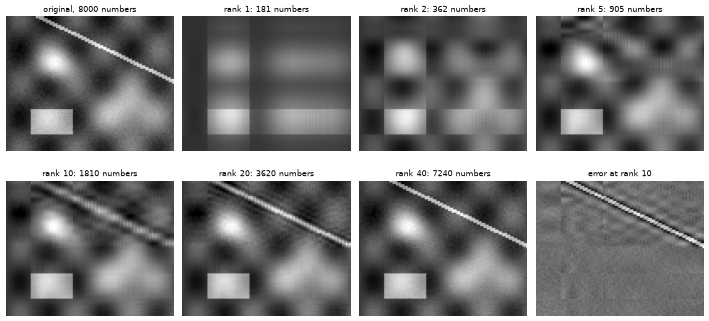

In [17]:
def make_image(m=80, n=100, seed=0):
    rng = np.random.default_rng(seed)
    yy, xx = np.mgrid[0:m, 0:n]
    r, c = yy / (m - 1), xx / (n - 1)
    img = 0.10 * c + 0.05 * r                                                       # smooth ramp
    img += 0.20 * np.sin(2 * np.pi * 3 * c) * np.cos(2 * np.pi * 2 * r)             # smooth waves
    img += 0.8 * np.exp(-((r - 0.35) ** 2 + (c - 0.30) ** 2) / (2 * 0.08 ** 2))     # round blob
    img += 0.6 * np.exp(-((r - 0.70) ** 2 + (c - 0.72) ** 2) / (2 * 0.12 ** 2))     # second blob
    img[55:70, 15:40] += 0.5                                                        # a bright rectangle
    img[np.abs((r - 0.15) - 0.6 * (c - 0.45)) < 0.015] += 0.6                       # a thin diagonal line
    img += 0.02 * rng.normal(size=(m, n))                                           # sensor noise
    return img

img = make_image()
m, n = img.shape
Ui, si, Vti = np.linalg.svd(img, full_matrices=False)

def rank_k(k):
    return (Ui[:, :k] * si[:k]) @ Vti[:k]

ranks = [1, 2, 5, 10, 20, 40]
fig, axes = plt.subplots(2, 4, figsize=(13, 6.4), dpi=55)
axes = axes.ravel()
axes[0].imshow(img, cmap="gray"); axes[0].set_title(f"original, {m * n} numbers")
for ax, k in zip(axes[1:7], ranks):
    ax.imshow(rank_k(k), cmap="gray", vmin=img.min(), vmax=img.max())
    ax.set_title(f"rank {k}: {k * (m + n + 1)} numbers")
axes[7].imshow(img - rank_k(10), cmap="gray"); axes[7].set_title("error at rank 10")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

The scree plot shows how fast the singular values fall, and the cumulative energy $\sum_{i \le k}\sigma_i^2 / \sum_i \sigma_i^2$ tells us how much of the picture each rank keeps. The 2-norm error of the rank-$k$ image is $\sigma_{k+1}$; the right panel checks this.

smallest k keeping 95% of the energy: 10 | 99%: 26
2-norm error equals sigma_{k+1} for k = 1..30: True


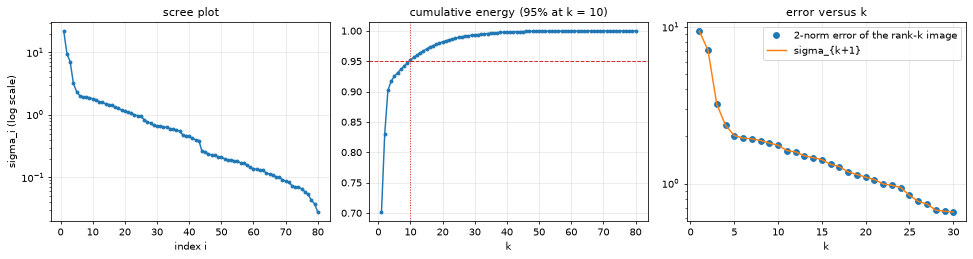

In [18]:
energy = np.cumsum(si ** 2) / np.sum(si ** 2)
k95 = int(np.searchsorted(energy, 0.95) + 1)
print("smallest k keeping 95% of the energy:", k95, "| 99%:", int(np.searchsorted(energy, 0.99) + 1))

ks = np.arange(1, 31)
err2 = np.array([np.linalg.norm(img - rank_k(k), 2) for k in ks])
print("2-norm error equals sigma_{k+1} for k = 1..30:", np.allclose(err2, si[ks]))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].semilogy(np.arange(1, len(si) + 1), si, "o-", ms=3)
axes[0].set_title("scree plot"); axes[0].set_xlabel("index i"); axes[0].set_ylabel("sigma_i (log scale)")
axes[1].plot(np.arange(1, len(si) + 1), energy, "o-", ms=3)
axes[1].axhline(0.95, color="C3", ls="--", lw=1); axes[1].axvline(k95, color="C3", ls=":", lw=1)
axes[1].set_title(f"cumulative energy (95% at k = {k95})"); axes[1].set_xlabel("k")
axes[2].semilogy(ks, err2, "o", label="2-norm error of the rank-k image")
axes[2].semilogy(ks, si[ks], "-", label="sigma_{k+1}")
axes[2].set_title("error versus k"); axes[2].set_xlabel("k"); axes[2].legend()
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Storage.** $A_k = U_k\Sigma_kV_k^\top$ needs $k(m + n + 1)$ numbers instead of $mn$. Compression only pays off while $k < mn/(m+n+1)$.

In [19]:
print(f"image is {m} x {n} = {m * n} numbers; break-even rank = {m * n / (m + n + 1):.1f}")
print(f"{'k':>3} {'stored':>7} {'% of original':>14} {'energy kept':>12} {'relative error':>15}")
for k in (1, 2, 5, 10, 20, 40):
    stored = k * (m + n + 1)
    rel_err = np.linalg.norm(img - rank_k(k), "fro") / np.linalg.norm(img, "fro")
    print(f"{k:3d} {stored:7d} {100 * stored / (m * n):13.1f}% {energy[k - 1]:12.4f} {rel_err:15.4f}")

image is 80 x 100 = 8000 numbers; break-even rank = 44.2
  k  stored  % of original  energy kept  relative error
  1     181           2.3%       0.7014          0.5465
  2     362           4.5%       0.8296          0.4128
  5     905          11.3%       0.9251          0.2737
 10    1810          22.6%       0.9518          0.2195
 20    3620          45.2%       0.9819          0.1345
 40    7240          90.5%       0.9981          0.0439


## 11. Noise reduction by dropping small singular values

A smooth signal of rank 3 plus random noise: the signal sits in the first three singular values, while the noise spreads over all of them at a smaller size. Keeping three terms removes most of the noise.

rank of the clean signal: 3
first 6 singular values of the noisy matrix: [99.5374 39.8672 19.6123  7.9707  7.6473  7.3686]
RMS error before: 0.5002 | after keeping 3 terms: 0.1453


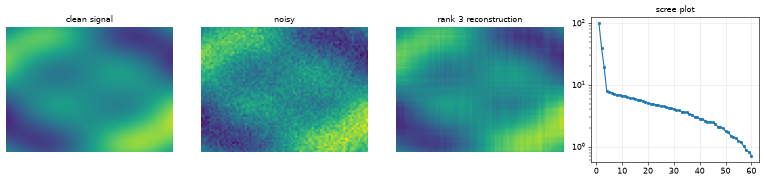

In [20]:
rng = np.random.default_rng(2)
mm, nn = 60, 80
x_ax, y_ax = np.linspace(0, 1, mm), np.linspace(0, 1, nn)
signal = (np.outer(np.sin(2 * np.pi * x_ax), np.cos(np.pi * y_ax))
          + 0.7 * np.outer(np.cos(3 * np.pi * x_ax), np.sin(2 * np.pi * y_ax))
          + 0.4 * np.outer(x_ax, y_ax)) * 3
noisy = signal + 0.5 * rng.normal(size=(mm, nn))
Un, sn, Vtn = np.linalg.svd(noisy, full_matrices=False)
denoised = (Un[:, :3] * sn[:3]) @ Vtn[:3]

rms = lambda E: np.sqrt(np.mean(E ** 2))
print("rank of the clean signal:", np.linalg.matrix_rank(signal))
print("first 6 singular values of the noisy matrix:", sn[:6])
print("RMS error before:", round(rms(noisy - signal), 4), "| after keeping 3 terms:", round(rms(denoised - signal), 4))

fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), dpi=55)
for ax, M_, title in zip(axes[:3], [signal, noisy, denoised], ["clean signal", "noisy", "rank 3 reconstruction"]):
    ax.imshow(M_, cmap="viridis", vmin=signal.min() - 1, vmax=signal.max() + 1); ax.set_title(title); ax.axis("off")
axes[3].semilogy(np.arange(1, len(sn) + 1), sn, "o-", ms=3); axes[3].set_title("scree plot"); axes[3].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 12. PCA through the SVD

For data centered at zero, $X_c = U\Sigma V^\top$ gives the covariance $C = X_c^\top X_c/(n-1) = V\,\frac{\Sigma^2}{n-1}\,V^\top$. So the principal axes are the columns of $V$ (the rows of `Vt`), the variances are $\sigma_i^2/(n-1)$, and the scores are $X_cV = U\Sigma$. We compare with `eigh` of the covariance matrix on 2D data, and with scikit-learn's `PCA` as a cross-check.

variances sigma^2/(n-1): [4.8064 0.2922] | eigenvalues of cov (descending): [4.8064 0.2922]
sigma^2/(n-1) equals the eigenvalues: True
axes match eigh (up to sign): True
scores X_c V equal U Sigma: True

scikit-learn explained_variance_: [4.8064 0.2922] | matches: True
scikit-learn components_ match Vt (up to sign): True
explained variance ratio: [0.9427 0.0573] | sigma^2 / sum sigma^2: [0.9427 0.0573]


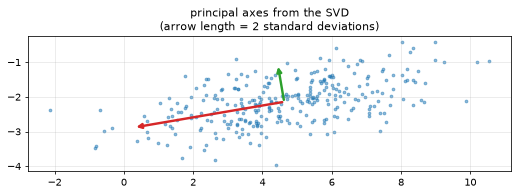

In [21]:
from sklearn.decomposition import PCA

rng = np.random.default_rng(7)
X2 = rng.normal(size=(300, 2)) @ np.array([[2.0, 0.0], [1.2, 0.7]]) + np.array([5.0, -2.0])
n_pts = len(X2)
mean2 = X2.mean(axis=0)
Xc2 = X2 - mean2
U2, s2, Vt2 = np.linalg.svd(Xc2, full_matrices=False)
w2, V2 = np.linalg.eigh(np.cov(X2.T))

print("variances sigma^2/(n-1):", s2 ** 2 / (n_pts - 1), "| eigenvalues of cov (descending):", w2[::-1])
print("sigma^2/(n-1) equals the eigenvalues:", np.allclose(s2 ** 2 / (n_pts - 1), w2[::-1]))
print("axes match eigh (up to sign):", np.allclose(np.abs(Vt2), np.abs(V2[:, ::-1].T)))
print("scores X_c V equal U Sigma:", np.allclose(Xc2 @ Vt2.T, U2 * s2))

pca = PCA(n_components=2).fit(X2)
print("\nscikit-learn explained_variance_:", pca.explained_variance_, "| matches:", np.allclose(pca.explained_variance_, s2 ** 2 / (n_pts - 1)))
print("scikit-learn components_ match Vt (up to sign):", np.allclose(np.abs(pca.components_), np.abs(Vt2)))
print("explained variance ratio:", pca.explained_variance_ratio_, "| sigma^2 / sum sigma^2:", s2 ** 2 / np.sum(s2 ** 2))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.scatter(X2[:, 0], X2[:, 1], s=8, alpha=0.5)
for i, color in enumerate(["C3", "C2"]):
    sd = s2[i] / np.sqrt(n_pts - 1)
    ax.annotate("", xy=mean2 + 2 * sd * Vt2[i], xytext=mean2, arrowprops=dict(arrowstyle="-|>", color=color, lw=2.5))
ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.set_title("principal axes from the SVD\n(arrow length = 2 standard deviations)")
plt.tight_layout()
plt.show()

The same in three dimensions (3D plots appear only in this notebook). We keep two components, reconstruct, and check that the squared Frobenius error equals the sum of the dropped $\sigma_i^2$.

variances match eigh: True | axes match: True
variance explained per axis: [0.9089 0.0832 0.0079]
scores shape: (200, 2) | squared error equals dropped sigma^2: True


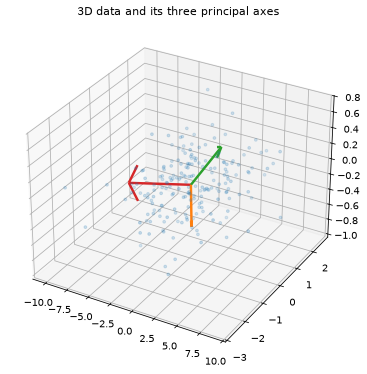

In [22]:
rng = np.random.default_rng(1)
X3 = rng.normal(size=(200, 3)) @ np.array([[3.0, 0.0, 0.0], [1.0, 1.0, 0.0], [0.5, 0.2, 0.3]])
mean3 = X3.mean(axis=0)
Xc3 = X3 - mean3
U3, s3, Vt3 = np.linalg.svd(Xc3, full_matrices=False)
w3, V3 = np.linalg.eigh(np.cov(X3.T))
print("variances match eigh:", np.allclose(s3 ** 2 / (len(X3) - 1), w3[::-1]), "| axes match:", np.allclose(np.abs(Vt3), np.abs(V3[:, ::-1].T)))
print("variance explained per axis:", s3 ** 2 / np.sum(s3 ** 2))

k = 2
scores3 = Xc3 @ Vt3[:k].T                                # 200 x 2
recon3 = scores3 @ Vt3[:k] + mean3
print("scores shape:", scores3.shape, "| squared error equals dropped sigma^2:",
      np.isclose(np.sum((X3 - recon3) ** 2), np.sum(s3[k:] ** 2)))

fig = plt.figure(figsize=(6.5, 5.5))
ax = fig.add_subplot(projection="3d")
ax.scatter(*X3.T, s=8, alpha=0.5)
for i, color in enumerate(["C3", "C2", "C1"]):
    sd = s3[i] / np.sqrt(len(X3) - 1)
    d = 2 * sd * Vt3[i]
    ax.quiver(*mean3, *d, color=color, lw=2.5, arrow_length_ratio=0.15)
ax.set_title("3D data and its three principal axes")
plt.tight_layout()
plt.show()

## 13. A small recommender from a rank-2 SVD

Five users rated four invented movies from 1 to 5, and a sixth user, "Sam", has not rated the second movie. We fill the hole with the column mean, take a rank-2 SVD, put the reconstructed value into the hole, and repeat. The low-rank structure (two tastes: action and romance) lets the first movie's rating guide the prediction for the second. A real recommender fits only the observed entries and is judged on held-out ratings; this is the idea in miniature.

In [23]:
movies = ["Space Raiders", "Laser Chase", "Moonlight Letters", "Cafe in Paris"]
R = np.array([[5, 5, 1, 1],
              [4, 5, 2, 1],
              [5, 4, 1, 2],
              [1, 2, 5, 5],
              [2, 1, 5, 4],
              [5, np.nan, 1, 2]])                       # Sam has not rated "Laser Chase"
missing = np.isnan(R)
filled = np.where(missing, np.nanmean(R, axis=0), R)
print("starting guess for the hole (column mean):", round(filled[5, 1], 2))
for _ in range(25):
    Ur, sr, Vtr = np.linalg.svd(filled, full_matrices=False)
    approx = (Ur[:, :2] * sr[:2]) @ Vtr[:2]
    filled = np.where(missing, approx, R)

print("singular values:", sr)
print("rank-2 reconstruction of Sam's row:", approx[5].round(2))
print("predicted rating for", movies[1], ":", round(approx[5, 1], 2), "(ratings are capped at 5)")
print("largest error on the entries we did know:", round(np.abs(approx - np.where(missing, 0, R))[~missing].max(), 2))
print("\nfirst two right singular vectors (one row per movie):")
for name, v1, v2 in zip(movies, Vtr[0], Vtr[1]):
    print(f"{name:18s} {v1:7.2f} {v2:7.2f}")

starting guess for the hole (column mean): 3.4
singular values: [15.4619  7.589   1.5195  1.1544]
rank-2 reconstruction of Sam's row: [5.03 5.03 1.34 1.61]
predicted rating for Laser Chase : 5.03 (ratings are capped at 5)
largest error on the entries we did know: 0.65

first two right singular vectors (one row per movie):
Space Raiders        -0.60    0.37
Laser Chase          -0.61    0.36
Moonlight Letters    -0.36   -0.66
Cafe in Paris        -0.37   -0.55


The first singular vector has the same sign for every movie: it is the overall level of liking. The second has opposite signs for the action movies and the romances: it is the action-versus-romance axis. Each user's scores on these two axes ($U\Sigma$) are their position in taste space.

## 14. Weight compression and LoRA parameter counts

Truncated SVD can shrink a weight matrix, but only if the matrix is close to low rank. We compare a matrix that has low-rank structure plus small noise with a purely random matrix of the same size. Then we count the trainable parameters of a LoRA update $BA$, which does not compute an SVD but assumes the update is low rank.

    matrix    k  stored fraction  relative error


structured   20            0.078           0.048
structured   64            0.250           0.041
structured  128            0.500           0.032


    random   20            0.078           0.929
    random   64            0.250           0.790
    random  128            0.500           0.614


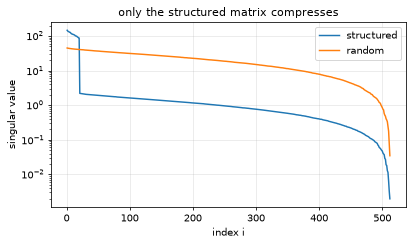

In [24]:
rng = np.random.default_rng(4)
d = 512
W_struct = rng.normal(size=(d, 20)) @ rng.normal(size=(20, d)) / np.sqrt(20) + 0.05 * rng.normal(size=(d, d))
W_random = rng.normal(size=(d, d))
print(f"{'matrix':>10} {'k':>4} {'stored fraction':>16} {'relative error':>15}")
sv = {}
for name, Wm in [("structured", W_struct), ("random", W_random)]:
    _, sw_, _ = np.linalg.svd(Wm)
    sv[name] = sw_
    for k in (20, 64, 128):
        frac = k * (2 * d + 1) / d ** 2
        rel = np.sqrt(np.sum(sw_[k:] ** 2) / np.sum(sw_ ** 2))
        print(f"{name:>10} {k:4d} {frac:16.3f} {rel:15.3f}")

plt.figure(figsize=(6, 3.6))
for name, vals in sv.items():
    plt.semilogy(np.arange(1, d + 1), vals, label=name)
plt.legend(); plt.xlabel("index i"); plt.ylabel("singular value"); plt.title("only the structured matrix compresses"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [25]:
# parameter counts: a full d x d weight matrix versus a LoRA update B A with B (d x r) and A (r x d)
d = 4096
full = d * d
print(f"full matrix: {full:,} numbers")
print(f"{'rank r':>7} {'LoRA params 2dr':>16} {'% of full':>10}")
for r_ in (1, 4, 8, 16, 64):
    print(f"{r_:7d} {2 * d * r_:16,d} {100 * 2 * d * r_ / full:9.2f}%")
print(f"truncated SVD at rank 64 stores {64 * (2 * d + 1):,} numbers ({100 * 64 * (2 * d + 1) / full:.1f}%)")
print(f"embedding table 50000 x 768 = {50000 * 768:,}; rank 100 stores {100 * (50000 + 768 + 1):,} ({100 * 100 * (50000 + 768 + 1) / (50000 * 768):.1f}%)")

# a tiny LoRA-style update: B starts at zero, so the update starts at zero and has rank at most r
rng = np.random.default_rng(0)
dd, rr = 8, 2
W0 = rng.normal(size=(dd, dd))
B_ = np.zeros((dd, rr)); A_ = rng.normal(size=(rr, dd))
print("\ninitial update B A is all zeros:", np.allclose(B_ @ A_, 0))
B_ = rng.normal(size=(dd, rr))
print("rank of B A after training B:", np.linalg.matrix_rank(B_ @ A_), "(never more than r =", rr, ")")
print("adapted weight W0 + B A has shape", (W0 + B_ @ A_).shape, "and rank", np.linalg.matrix_rank(W0 + B_ @ A_), "(the update is low rank, the sum need not be)")

full matrix: 16,777,216 numbers
 rank r  LoRA params 2dr  % of full
      1            8,192      0.05%
      4           32,768      0.20%
      8           65,536      0.39%
     16          131,072      0.78%
     64          524,288      3.12%
truncated SVD at rank 64 stores 524,352 numbers (3.1%)
embedding table 50000 x 768 = 38,400,000; rank 100 stores 5,076,900 (13.2%)

initial update B A is all zeros: True
rank of B A after training B: 2 (never more than r = 2 )
adapted weight W0 + B A has shape (8, 8) and rank 8 (the update is low rank, the sum need not be)


## What you did

You saw the SVD as rotate, stretch, rotate, derived it from $A^\top A$, read the four subspaces, the rank, and the condition number from it, built the pseudoinverse and the minimum-norm solution, verified Eckart-Young, compressed an image, ran PCA through the SVD, filled a rating matrix, and counted the parameters of compressed and LoRA-style weights. Back to the [topic README](README.md) for the summary and the exercises.